
# STRATUM — Model Serialization and Inference Engine

## Phase 3 — Step 3.9

### Objective

Prepare the final evaluated virtual metrology
models for reproducible application integration.

### Selected Models

- Thickness: XGB-4.
- Sheet resistance: RES-XGB-2.

### Methodology

1. Verify final evaluation artifacts.
2. Reproduce eligible development membership.
3. Refit the frozen model configurations.
4. Verify final held-out metric reproduction.
5. Recompute final-model global TreeSHAP evidence.
6. Define the inference input and output contracts.
7. Serialize and version the fitted models.
8. Verify artifact checksums and runtime compatibility.
9. Reload and compare fitted model predictions.
10. Investigate inference input validation.
11. Verify dual-target prediction and explanations.
12. Execute automated integration tests.

No additional hyperparameter selection or
test-based model replacement will occur.

The resulting artifacts are intended for
the STRATUM academic application.

Prediction estimates and input warnings
do not constitute wafer acceptance decisions.

In [1]:

from pathlib import Path
import sys
import json
import hashlib
import time
import subprocess

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
import xgboost
import joblib

sns.set_theme(style="whitegrid")

current_dir = Path.cwd()

if (current_dir / "ml").is_dir():

    project_root = current_dir

elif (current_dir.parent / "ml").is_dir():

    project_root = current_dir.parent

else:

    raise FileNotFoundError(
        "Cannot locate STRATUM project root."
    )

if str(project_root) not in sys.path:

    sys.path.insert(0, str(project_root))

from ml.preprocessing import (
    get_feature_columns,
)

from ml.data_split import (
    chronological_lot_split,
)

from ml.cross_validation import (
    prepare_chronological_data,
    purge_training_overlap,
    fit_candidate_model,
)

from ml.resistance_models import (
    fit_resistance_candidate,
)

from ml.evaluation import (
    evaluate_regression,
)

from ml.explainability import (
    unwrap_fitted_pipeline,
    get_transformed_feature_names,
    calculate_tree_contributions,
    aggregate_raw_contributions,
    global_shap_importance,
)

from ml.model_registry import (
    TARGETS,
    runtime_versions,
    sha256_file,
    read_json,
    write_json,
    save_model_bundle,
    verify_bundle,
    load_model_bundle,
)

from ml.inference import (
    StratumInferenceEngine,
    InputValidationError,
    PredictionError,
)

MODEL_VERSION = "1.0.0"

MODEL_N_JOBS = -1

RANDOM_STATE = 42

results_dir = project_root / "ml" / "results"

artifact_root = project_root / "ml" / "artifacts"

bundle_path = artifact_root / MODEL_VERSION

print("STRATUM - Model Serialization")

print("Model version:", MODEL_VERSION)

print(json.dumps(runtime_versions(), indent=4))

print("\nAll imports successful.")

STRATUM - Model Serialization
Model version: 1.0.0
{
    "python": "3.14.3",
    "numpy": "2.5.4",
    "pandas": "3.1.0",
    "scipy": "1.18.1",
    "scikit-learn": "1.9.1",
    "xgboost": "3.4.1",
    "joblib": "1.6.0"
}

All imports successful.


## 1. Final Research Artifact Verification

Load the final evaluation protocol,
evaluation results and training-fitted
input warning profile.

Verify dataset fingerprints, population
fingerprints, model configurations and
software versions before reconstructing
the final fitted models.

In [2]:

# Load authoritative final evaluation artifacts

evaluation = read_json(
    results_dir / "final_model_evaluation.json"
)

protocol = read_json(
    results_dir / "final_evaluation_protocol.json"
)

warning_profile = read_json(
    results_dir / "input_warning_profile.json"
)

split_manifest = read_json(
    project_root / "docs" / "split_manifest.json"
)

assert evaluation["protocol"] == protocol

assert evaluation["dataset_sha256"] == (
    protocol["dataset_sha256"]
)

assert warning_profile["dataset_sha256"] == (
    protocol["dataset_sha256"]
)

assert split_manifest["dataset_sha256"] == (
    protocol["dataset_sha256"]
)

assert evaluation["model_configurations"] == (
    protocol["model_configurations"]
)

assert evaluation["input_columns"] == (
    protocol["input_columns"]
)

assert evaluation["model_n_jobs"] == MODEL_N_JOBS

assert evaluation["sklearn_version"] == (
    sklearn.__version__
)

assert evaluation["xgboost_version"] == (
    xgboost.__version__
)

assert not protocol[
    "further_hyperparameter_selection"
]

assert not protocol[
    "test_based_model_replacement"
]

partition = evaluation["partition_summary"]

assert warning_profile[
    "development_population_sha256"
] == partition[
    "development_population_sha256"
]

model_configs = evaluation[
    "model_configurations"
]

input_columns = evaluation[
    "input_columns"
]

apc_features = input_columns[
    "mean_thickness"
]

assert len(apc_features) == 110

assert input_columns[
    "mean_resistance"
] == apc_features + ["equipment"]

assert model_configs[
    "mean_thickness"
]["name"] == "XGB-4"

assert model_configs[
    "mean_resistance"
]["name"] == "RES-XGB-2"

print("Final evaluation artifacts: VERIFIED")

print(json.dumps(partition, indent=4))

display(
    pd.DataFrame(
        evaluation["selected_model_comparison"]
    )
)

Final evaluation artifacts: VERIFIED
{
    "original_training_records": 3331,
    "original_validation_records": 834,
    "combined_development_records": 4165,
    "additional_purged_records": 0,
    "eligible_development_records": 4165,
    "final_test_records": 1042,
    "development_lots": 2361,
    "final_test_lots": 590,
    "development_batches": 4165,
    "final_test_batches": 1042,
    "development_start": "2021-07-31 06:51:54",
    "development_end": "2024-07-31 13:58:35",
    "final_test_start": "2024-07-31 17:05:11",
    "final_test_end": "2025-05-31 17:04:14",
    "development_population_sha256": "42c3b7f4fce9c57743b3abf78b64f34582decb131d72e70a017d6e5bef0f6f7d",
    "test_population_sha256": "38462362df82611e0671347035e6888c60ee8c5e6f25b42b0bfa70410cfd882f"
}


,Target,Candidate,Reference Baseline,Baseline MAE,Final Test MAE,Final Test RMSE,Final Test R2,Final Test MAPE (%),Final Test Bias,MAE Improvement (%),Non-Positive Predictions
0,mean_thickness,XGB-4,Equipment Mean,1.960417,1.193555,1.555422,0.583907,0.786179,-0.034797,39.117303,0
1,mean_resistance,RES-XGB-2,Global Mean,0.000040,0.000024,0.000032,0.570150,0.836203,0.000007,39.583959,0


## 2. Final Development Population Reproduction

Reproduce the original chronological partitions
from the verified dataset.

Combine original training and validation
observations without restoring previously
purged records.

Apply the same lot and batch overlap
protection used during final evaluation.

Verify ordered population fingerprints
against Notebook 16.

In [3]:

# Reproduce exact dataset and population membership

csv_path = (
    project_root
    / "data"
    / "raw"
    / "apc_spc_AlCu_inputs_outputs.csv"
)

assert sha256_file(csv_path) == (
    evaluation["dataset_sha256"]
)

df = pd.read_csv(
    csv_path,
    sep=";",
    skiprows=1,
    low_memory=False,
)

assert df.shape == (5208, 178)

train_df, val_df, test_df, split_info = (
    chronological_lot_split(
        df,

        test_fraction=split_manifest[
            "test_fraction"
        ],

        validation_fraction=split_manifest[
            "validation_fraction_of_development"
        ],
    )
)

assert split_info == split_manifest[
    "split_summary"
]

actual_apc_features, _ = get_feature_columns(df)

assert actual_apc_features == apc_features

train_df = prepare_chronological_data(train_df)

val_df = prepare_chronological_data(val_df)

test_df = prepare_chronological_data(test_df)

combined_development_df = (
    prepare_chronological_data(
        pd.concat(
            [train_df, val_df],

            ignore_index=True,
        )
    )
)

development_df, purge_info = (
    purge_training_overlap(
        combined_development_df,
        test_df,
    )
)

development_df = prepare_chronological_data(
    development_df
)

assert purge_info == evaluation[
    "partition_purge_info"
]

assert len(development_df) == 4165

assert len(test_df) == 1042


def population_sha256(frame):

    payload = json.dumps(
        frame["wafer_id"].astype(str).tolist(),

        ensure_ascii=False,

        separators=(",", ":"),
    )

    return hashlib.sha256(
        payload.encode("utf-8")
    ).hexdigest()


assert population_sha256(
    development_df
) == partition[
    "development_population_sha256"
]

assert population_sha256(
    test_df
) == partition[
    "test_population_sha256"
]

for column in ["wafer_id", "lot", "bat_id"]:

    assert not (
        set(development_df[column])

        & set(test_df[column])
    )

assert (
    pd.to_datetime(
        development_df["runend"]
    ).max()

    < pd.to_datetime(
        test_df["runstart"]
    ).min()
)

print("Dataset fingerprint: VERIFIED")

print("Development membership: VERIFIED")

print("Test membership: VERIFIED")

print("Eligible development:", len(development_df))

print("Reserved test:", len(test_df))

Dataset fingerprint: VERIFIED
Development membership: VERIFIED
Test membership: VERIFIED
Eligible development: 4165
Reserved test: 1042


## 3. Final Model Reconstruction

Refit the frozen configurations using
the exact eligible development population.

Retain the original training thread
configuration, random state and selected
boosting-round counts.

Verify final fitted feature dimensions
and target transformation parameters.

In [4]:

# Refit both frozen model configurations

final_models = {}

fitting_rows = []

reference_features = pd.DataFrame(
    evaluation["final_feature_summary"]
).set_index("Target")

for target in TARGETS:

    candidate = model_configs[target]

    rounds = candidate["parameters"][
        "n_estimators"
    ]

    start = time.perf_counter()

    if target == "mean_thickness":

        model, fit_info = fit_candidate_model(
            candidate=candidate,

            training_data=development_df,

            apc_features=apc_features,

            target=target,

            n_jobs=MODEL_N_JOBS,

            fixed_boosting_rounds=rounds,
        )

    else:

        model, fit_info = fit_resistance_candidate(
            candidate=candidate,

            training_data=development_df,

            apc_features=apc_features,

            target=target,

            n_jobs=MODEL_N_JOBS,

            fixed_boosting_rounds=rounds,
        )

    elapsed = time.perf_counter() - start

    pipeline, target_mean, target_scale = (
        unwrap_fitted_pipeline(model)
    )

    regressor = pipeline.named_steps["regressor"]

    booster = regressor.get_booster()

    feature_names = get_transformed_feature_names(
        model
    )

    reference = reference_features.loc[target]

    assert booster.num_boosted_rounds() == rounds

    assert booster.num_features() == len(
        feature_names
    )

    assert len(feature_names) == int(
        reference["Transformed Features"]
    )

    assert regressor.get_params()[
        "early_stopping_rounds"
    ] is None

    np.testing.assert_allclose(
        target_mean,
        reference["Target Mean"],
        rtol=1e-12,
        atol=1e-15,
    )

    np.testing.assert_allclose(
        target_scale,
        reference["Target Scale"],
        rtol=1e-12,
        atol=1e-15,
    )

    final_models[target] = model

    fitting_rows.append({
        "Target": target,

        "Candidate": candidate["name"],

        "Development Records": len(development_df),

        "Raw Features": len(input_columns[target]),

        "Transformed Features": len(feature_names),

        "Boosting Rounds": rounds,

        "Target Mean": target_mean,

        "Target Scale": target_scale,

        "Training Time (s)": elapsed,
    })

    print(f"{target}: Reconstructed successfully.")

fitting_summary = pd.DataFrame(fitting_rows)

display(fitting_summary)

print("\nFinal model internals: VERIFIED")

mean_thickness: Reconstructed successfully.
mean_resistance: Reconstructed successfully.


,Target,Candidate,Development Records,Raw Features,Transformed Features,Boosting Rounds,Target Mean,Target Scale,Training Time (s)
0,mean_thickness,XGB-4,4165,110,157,820,0.000000,1.000000,4.086394
1,mean_resistance,RES-XGB-2,4165,111,173,837,0.002898,0.000054,4.218400



Final model internals: VERIFIED


## 4. Final Metric Reproduction

Compare reconstructed-model performance
with the saved final held-out metrics.

The reserved test data are used only
for reproducibility verification.

No model selection, feature selection,
bias correction or hyperparameter
adjustment will use these results.

Metric agreement supports numerical
reproducibility but does not independently
prove identical fitted tree structures.

In [5]:

# Reproduce saved final held-out regression metrics

reference_metrics = pd.DataFrame(
    evaluation["final_test_metrics"]
)

reproduction_rows = []

reconstructed_test_predictions = {}

for target in TARGETS:

    candidate = model_configs[target]["name"]

    predicted = np.asarray(
        final_models[target].predict(
            test_df[input_columns[target]]
        ),
        dtype=float,
    )

    assert predicted.shape == (1042,)

    assert np.isfinite(predicted).all()

    assert (predicted > 0).all()

    metrics = evaluate_regression(
        test_df[target],
        predicted,
    )

    matched = reference_metrics.loc[
        (reference_metrics["Target"] == target)

        &

        (reference_metrics["Model"] == candidate)
    ]

    assert len(matched) == 1

    reference = matched.iloc[0]

    for metric in [
        "MAE",
        "RMSE",
        "R2",
        "MAPE (%)",
        "Bias",
    ]:

        np.testing.assert_allclose(
            metrics[metric],

            reference[metric],

            rtol=1e-6,

            atol=(
                1e-12

                if target == "mean_resistance"

                else 1e-8
            ),

            err_msg=(
                f"Reproduction failure: "
                f"{target}, {metric}"
            ),
        )

    reconstructed_test_predictions[
        target
    ] = predicted

    reproduction_rows.append({
        "Target": target,

        "Candidate": candidate,

        **metrics,

        "Reference MAE": float(
            reference["MAE"]
        ),

        "MAE Difference": abs(
            metrics["MAE"]
            - reference["MAE"]
        ),

        "Reference R2": float(
            reference["R2"]
        ),

        "R2 Difference": abs(
            metrics["R2"]
            - reference["R2"]
        ),

        "Passed": True,
    })

reproduction_summary = pd.DataFrame(
    reproduction_rows
)

display(
    reproduction_summary.round(12)
)

print("Final held-out metric reproduction: PASSED")

,Target,Candidate,MAE,RMSE,R2,MAPE (%),Bias,Reference MAE,MAE Difference,Reference R2,R2 Difference,Passed
0,mean_thickness,XGB-4,1.193555,1.555422,0.583907,0.786179,-0.034797,1.193555,0.0,0.583907,0.0,True
1,mean_resistance,RES-XGB-2,0.000024,0.000032,0.570150,0.836203,0.000007,0.000024,0.0,0.570150,0.0,True


Final held-out metric reproduction: PASSED


## 5. Final-Model Global Explainability

Recompute native XGBoost TreeSHAP
contributions for the final fitted models.

Use the complete eligible development
population as the explanation population.

Aggregate transformed-feature attributions
by originating raw process input.

Preserve original target scales and
verify additive reconstruction.

This analysis describes final fitted model
behaviour on development observations.

It does not represent independent
held-out feature-importance evidence.

In [6]:

# Compute final-model global TreeSHAP importance

global_importance_tables = {}

global_explainability = {
    "project": "STRATUM",

    "model_version": MODEL_VERSION,

    "dataset_sha256": evaluation[
        "dataset_sha256"
    ],

    "development_population_sha256": partition[
        "development_population_sha256"
    ],

    "explanation_population": (
        "eligible_combined_development"
    ),

    "records": len(development_df),

    "method": "Native XGBoost TreeSHAP",

    "interpretation_warning": (
        "Feature attribution describes fitted "
        "model behaviour, not physical causality."
    ),

    "targets": {},
}

for target in TARGETS:

    print(
        f"Calculating final TreeSHAP: {target}",
        flush=True,
    )

    start = time.perf_counter()

    explanation = calculate_tree_contributions(
        final_models[target],

        development_df[input_columns[target]],
    )

    grouped = aggregate_raw_contributions(
        explanation,

        apc_features,
    )

    assert len(grouped) == len(development_df)

    assert set(grouped.columns) == set(
        input_columns[target]
    )

    importance = global_shap_importance(
        grouped
    )

    global_importance_tables[target] = (
        importance
    )

    elapsed = time.perf_counter() - start

    global_explainability["targets"][
        target
    ] = {
        "candidate": model_configs[target]["name"],

        "records": len(grouped),

        "raw_input_groups": grouped.shape[1],

        "transformed_features": len(
            explanation["feature_names"]
        ),

        "mean_base_prediction": float(
            explanation["base_predictions"].mean()
        ),

        "maximum_reconstruction_error": float(
            explanation["maximum_reconstruction_error"]
        ),

        "mean_reconstruction_error": float(
            explanation["mean_reconstruction_error"]
        ),

        "calculation_seconds": elapsed,

        "global_importance": (
            importance.astype(object)
            .where(pd.notna(importance), None)
            .to_dict(orient="records")
        ),
    }

    display(importance.head(15))

print("\nFinal-model global explanations: COMPLETE")

Calculating final TreeSHAP: mean_thickness


,Feature,Mean Absolute Contribution,Mean Signed Contribution,Relative Importance (%)
0,T_DEP1_PROCESS,0.732405,0.053410,13.032520
1,T_RECIPE_ENG,0.610347,0.003341,10.860595
2,LIFE_TARGET_DEP1_S,0.291729,0.033829,5.191068
3,LIFE_TARGET_DEP1_A,0.259567,-0.032389,4.618770
4,VOLTS_TARGET_RUN_A,0.237391,0.000398,4.224166
5,VOLTS_TARGET_RE_A,0.172422,0.029456,3.068093
6,AMPS_TARGET_20_90_DEP1_SPS_X,0.163679,0.024521,2.912530
7,DCBIAS_PLATEN_DEP1_A,0.152703,-0.037346,2.717223
8,DCBIAS_PLATEN_DEP1_I,0.148220,-0.033621,2.637444
9,LIFE_TARGET_RUN_A,0.134414,-0.025971,2.391789


Calculating final TreeSHAP: mean_resistance


,Feature,Mean Absolute Contribution,Mean Signed Contribution,Relative Importance (%)
0,T_DEP1_PROCESS,0.000014,-7.657832e-07,12.476551
1,T_RECIPE_ENG,0.000011,7.236225e-07,9.829552
2,LIFE_TARGET_DEP1_S,0.000005,-6.637249e-07,4.072595
3,VOLTS_TARGET_SPS_DEP1_A,0.000004,-9.913362e-08,3.487947
4,VOLTS_TARGET_RE_A,0.000004,-6.944699e-07,3.052635
5,LIFE_TARGET_DEP1_A,0.000003,1.655667e-07,2.796209
6,AMPS_TARGET_20_90_DEP1_SPS_X,0.000003,-2.717306e-07,2.527433
7,RGA_FUNCTION_DAY,0.000003,-5.988357e-09,2.517262
8,VOLTS_TARGET_RUN_A,0.000003,-3.556723e-07,2.433739
9,DCBIAS_PLATEN_DEP1_A,0.000003,4.925241e-07,2.225486



Final-model global explanations: COMPLETE


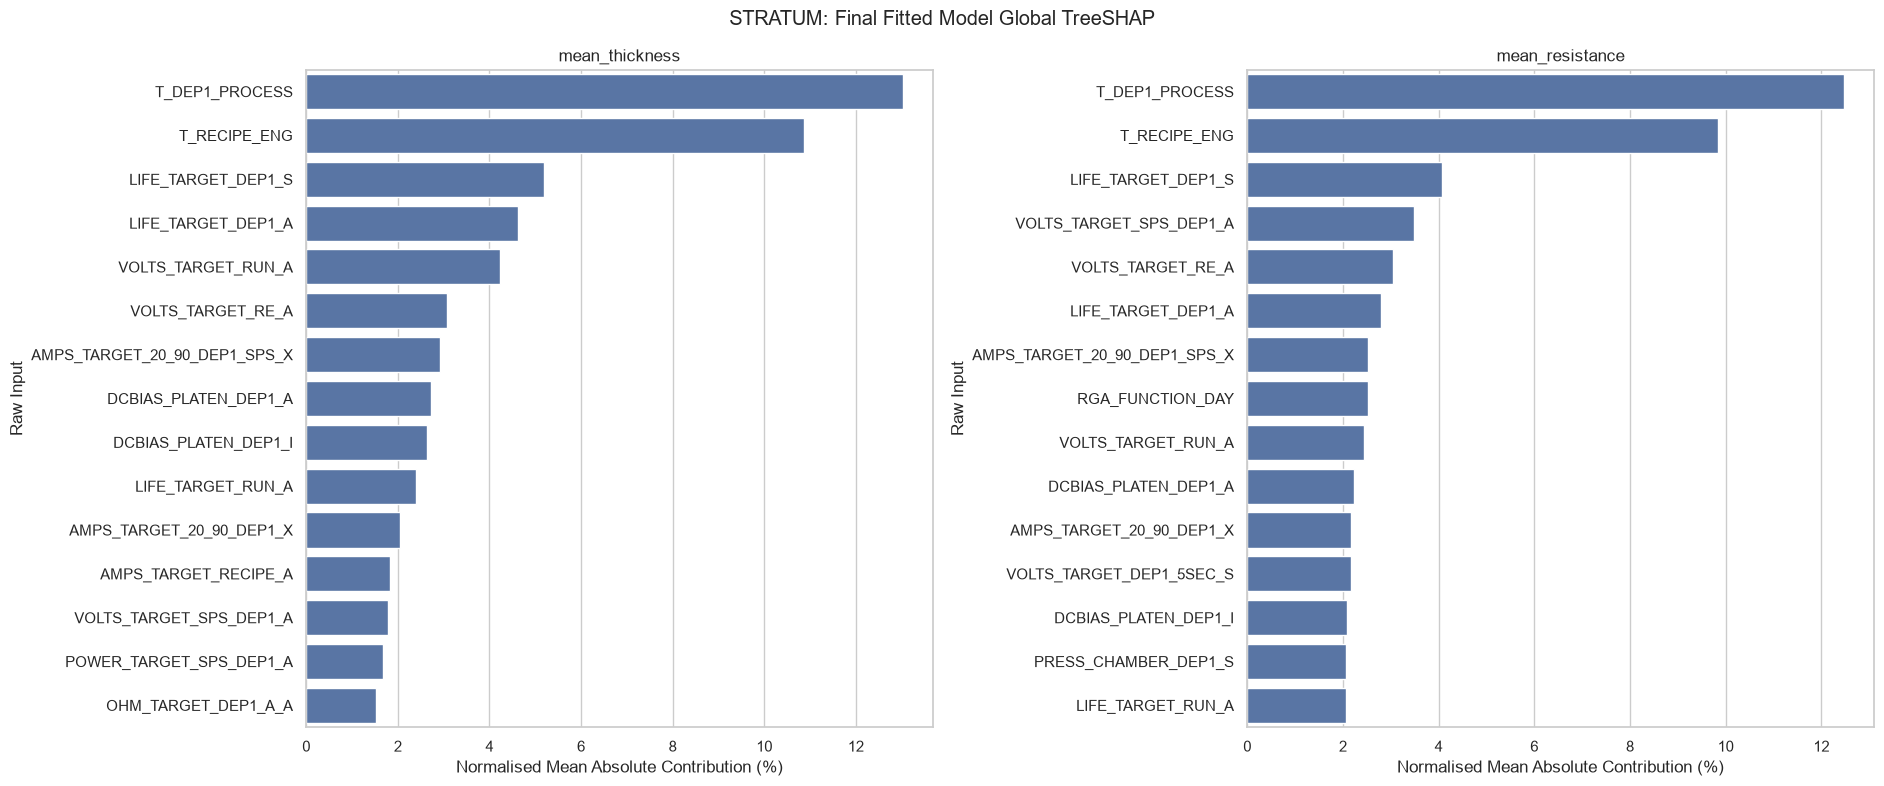

In [7]:

# Visualise global TreeSHAP for final fitted models

fig, axes = plt.subplots(
    1, 2, figsize=(19, 8)
)

for ax, target in zip(axes, TARGETS):

    plot_data = global_importance_tables[
        target
    ].copy()

    total = plot_data[
        "Mean Absolute Contribution"
    ].sum()

    assert total > 0

    plot_data["Importance (%)"] = (
        plot_data["Mean Absolute Contribution"]
        / total
        * 100
    )

    plot_data = (
        plot_data
        .sort_values(
            "Importance (%)",
            ascending=False,
        )
        .head(15)
    )

    sns.barplot(
        data=plot_data,

        x="Importance (%)",

        y="Feature",

        ax=ax,
    )

    ax.set_title(target)

    ax.set_xlabel(
        "Normalised Mean Absolute Contribution (%)"
    )

    ax.set_ylabel("Raw Input")

plt.suptitle(
    "STRATUM: Final Fitted Model Global TreeSHAP"
)

plt.tight_layout()
plt.show()


In [8]:

# Compare final-model shared APC predictor rankings

from scipy.stats import spearmanr

thickness_importance = (
    global_importance_tables["mean_thickness"]
    .set_index("Feature")
)

resistance_importance = (
    global_importance_tables["mean_resistance"]
    .set_index("Feature")
)

shared_importance = pd.DataFrame({
    "Thickness": thickness_importance.loc[
        apc_features,
        "Mean Absolute Contribution",
    ],

    "Resistance": resistance_importance.loc[
        apc_features,
        "Mean Absolute Contribution",
    ],
})

correlation = float(
    spearmanr(
        shared_importance["Thickness"],

        shared_importance["Resistance"],
    ).statistic
)

thickness_top10 = set(
    shared_importance["Thickness"]
    .nlargest(10)
    .index
)

resistance_top10 = set(
    shared_importance["Resistance"]
    .nlargest(10)
    .index
)

shared_top10 = sorted(
    thickness_top10 & resistance_top10
)

global_explainability[
    "cross_target_comparison"
] = {
    "shared_apc_features": len(apc_features),

    "spearman_rank_correlation": correlation,

    "top10_overlap_count": len(shared_top10),

    "shared_top10_features": shared_top10,
}

print(
    json.dumps(
        global_explainability[
            "cross_target_comparison"
        ],

        indent=4,
    )
)

{
    "shared_apc_features": 110,
    "spearman_rank_correlation": 0.8924599328269053,
    "top10_overlap_count": 8,
    "shared_top10_features": [
        "AMPS_TARGET_20_90_DEP1_SPS_X",
        "DCBIAS_PLATEN_DEP1_A",
        "LIFE_TARGET_DEP1_A",
        "LIFE_TARGET_DEP1_S",
        "T_DEP1_PROCESS",
        "T_RECIPE_ENG",
        "VOLTS_TARGET_RE_A",
        "VOLTS_TARGET_RUN_A"
    ]
}


## 6. Inference Schema and Model Metadata

Define the required APC feature names,
equipment metadata and target-specific
input configurations.

Specify valid missing-value handling
and numerical input requirements.

Record model identifiers, output scales,
research provenance and interpretation
restrictions.

No physical measurement units or
engineering acceptance limits are invented.

In [9]:

# Define the inference schema

input_schema = {
    "schema_version": "1.0.0",

    "apc_features": apc_features,

    "apc_feature_count": len(apc_features),

    "required_columns": (
        apc_features + ["equipment"]
    ),

    "model_inputs": input_columns,

    "fields": {
        **{
            feature: {
                "type": "number",

                "required": True,

                "nullable": True,

                "allow_infinity": False,
            }

            for feature in apc_features
        },

        "equipment": {
            "type": "string",

            "required": True,

            "nullable": True,

            "known_categories": warning_profile[
                "known_equipment"
            ],

            "unknown_category_policy": (
                "allow_with_warning"
            ),
        },
    },

    "all_apc_missing_policy": "reject_record",

    "unexpected_columns_policy": "reject",

    "numeric_string_policy": "reject",

    "duplicate_columns_policy": "reject",

    "missing_columns_policy": "reject",

    "output_targets": {
        "mean_thickness": {
            "type": "number",

            "output_scale": "dataset_units",

            "physical_unit_verified": False,
        },

        "mean_resistance": {
            "type": "number",

            "output_scale": "dataset_units",

            "physical_unit_verified": False,
        },
    },
}

assert len(input_schema["fields"]) == 111

assert len(
    input_schema["required_columns"]
) == 111

print("Input schema: COMPLETE")

print("Required columns: 111")

print("APC features: 110")

print("Equipment fields: 1")

display(
    pd.DataFrame(
        input_schema["fields"]
    ).T.head(10)
)

Input schema: COMPLETE
Required columns: 111
APC features: 110
Equipment fields: 1


,type,required,nullable,allow_infinity,known_categories,unknown_category_policy
AMPS_TARGET_20_90_DELTA_DEP1,number,True,True,False,NaN,NaN
AMPS_TARGET_20_90_DEP1_M,number,True,True,False,NaN,NaN
AMPS_TARGET_20_90_DEP1_SPS,number,True,True,False,NaN,NaN
AMPS_TARGET_20_90_DEP1_SPS_M,number,True,True,False,NaN,NaN
AMPS_TARGET_20_90_DEP1_SPS_X,number,True,True,False,NaN,NaN
AMPS_TARGET_20_90_DEP1_X,number,True,True,False,NaN,NaN
AMPS_TARGET_20_95_DELTA_DEP1,number,True,True,False,NaN,NaN
AMPS_TARGET_20_95_DEP1_M,number,True,True,False,NaN,NaN
AMPS_TARGET_20_95_DEP1_SPS,number,True,True,False,NaN,NaN
AMPS_TARGET_20_95_DEP1_SPS_M,number,True,True,False,NaN,NaN


In [10]:

from datetime import datetime, timezone

model_metadata = {
    "project": "STRATUM",

    "model_version": MODEL_VERSION,

    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "dataset_name": (
        "Infineon AlCu PVD manufacturing data"
    ),

    "dataset_sha256": evaluation[
        "dataset_sha256"
    ],

    "development_population_sha256": partition[
        "development_population_sha256"
    ],

    "test_population_sha256": partition[
        "test_population_sha256"
    ],

    "development_records": len(development_df),

    "final_test_records": len(test_df),

    "model_configurations": model_configs,

    "model_n_jobs": MODEL_N_JOBS,

    "random_state": RANDOM_STATE,

    "targets": list(TARGETS),

    "training_partition": (
        "eligible_combined_development"
    ),

    "evaluation_partition": (
        "reserved_chronological_final_test"
    ),

    "global_explanation_partition": (
        "eligible_combined_development"
    ),

    "final_feature_summary": evaluation[
        "final_feature_summary"
    ],

    "reference_baselines": evaluation[
        "reference_baselines"
    ],

    "source_artifact_checksums": {
        filename: sha256_file(
            results_dir / filename
        )

        for filename in [
            "final_evaluation_protocol.json",

            "final_model_evaluation.json",

            "input_warning_profile.json",
        ]
    },

    "intended_use": (
        "Academic semiconductor virtual metrology "
        "and engineering decision support."
    ),

    "prediction_time": (
        "Intended after process execution and "
        "before physical metrology, subject to "
        "operational input availability verification."
    ),

    "limitations": evaluation["limitations"],

    "acceptance_classification": False,

    "calibrated_prediction_uncertainty": False,

    "external_validation": False,

    "test_based_model_selection": False,
}

print(
    json.dumps(
        model_metadata,
        indent=4,
    )
)

{
    "project": "STRATUM",
    "model_version": "1.0.0",
    "created_at_utc": "2026-11-28T14:44:50.908433+00:00",
    "dataset_name": "Infineon AlCu PVD manufacturing data",
    "dataset_sha256": "32af2d4508da45b0c7235db7b6923f3e1b19729d91e3b593a0d0135eba6a74b1",
    "development_population_sha256": "42c3b7f4fce9c57743b3abf78b64f34582decb131d72e70a017d6e5bef0f6f7d",
    "test_population_sha256": "38462362df82611e0671347035e6888c60ee8c5e6f25b42b0bfa70410cfd882f",
    "development_records": 4165,
    "final_test_records": 1042,
    "model_configurations": {
        "mean_thickness": {
            "name": "XGB-4",
            "algorithm": "XGBoost",
            "include_equipment": false,
            "parameters": {
                "missing_strategy": "median",
                "max_depth": 4,
                "learning_rate": 0.025,
                "n_estimators": 820,
                "min_child_weight": 5,
                "reg_alpha": 0.1,
                "reg_lambda": 5.0,
            

## 7. Versioned Model Bundle Creation

Serialize the complete fitted pipelines
using joblib.

Preserve preprocessing, equipment encoding,
XGBoost regression and resistance target
transformation within the fitted artifacts.

Associate the models with input schemas,
evaluation results, warning profiles and
global explainability evidence.

Generate SHA256 checksums for every
bundle artifact.

Existing model versions must not be
silently overwritten.

In [11]:

# Create the versioned STRATUM model bundle

bundle_path = save_model_bundle(
    artifact_root=artifact_root,

    model_version=MODEL_VERSION,

    models=final_models,

    metadata=model_metadata,

    input_schema=input_schema,

    warning_profile=warning_profile,

    global_explainability=global_explainability,

    evaluation=evaluation,
)

print("Model bundle successfully created.")

print("Location:", bundle_path)

Model bundle successfully created.
Location: c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\ml\artifacts\1.0.0


In [12]:

# Verify saved artifact checksums and file sizes

artifact_manifest = verify_bundle(
    bundle_path,
    check_runtime=True,
)

artifact_rows = []

for filename, checksum in (
    artifact_manifest["files"].items()
):

    path = bundle_path / filename

    artifact_rows.append({
        "Artifact": filename,

        "Bytes": path.stat().st_size,

        "Size (KiB)": (
            path.stat().st_size / 1024
        ),

        "SHA256": checksum,

        "Verified": (
            sha256_file(path) == checksum
        ),
    })

artifact_summary = pd.DataFrame(
    artifact_rows
)

display(artifact_summary)

assert artifact_summary[
    "Verified"
].all()

print(
    "Total bundle size (MiB):",

    sum(
        path.stat().st_size

        for path in bundle_path.iterdir()

        if path.is_file()
    ) / 1024**2,
)

print("\nAll artifact checksums: VERIFIED")

,Artifact,Bytes,Size (KiB),SHA256,Verified
0,evaluation.json,140794,137.494141,88064998917147ca601b22dfaacdc9249a2b8daecd4c66...,True
1,global_explainability.json,69878,68.240234,28f4ca0d743f0bc8f0fed34e3a5c0824db07a299675194...,True
2,input_schema.json,36107,35.260742,f4cd47c569c4e26141aa3cebebc0f546c749cd2dcc96d7...,True
3,input_warning_profile.json,24096,23.531250,1615eb1170e9155d1bbe4e94a9753da3d975905e36c185...,True
4,metadata.json,5213,5.090820,af7769f1d0d016d7976a4c4dbb40f0ee665c10e6c7150f...,True
5,resistance.joblib,339373,331.418945,d1383ce1c760efea0a67d97eb4c18d9b70c55fd5aa3b84...,True
6,thickness.joblib,333304,325.492188,8f857ecc4e8ee3c8ec5596773685383baabafbed02dda6...,True


Total bundle size (MiB): 0.9055929183959961

All artifact checksums: VERIFIED


## 8. Serialization Round-Trip Verification

Reload both fitted pipelines from their
permanent model artifacts.

Verify prediction agreement before and
after serialization on the reserved
final test observations.

Verify fitted feature ordering,
boosting-round counts and resistance
target transformation parameters.

No model refitting occurs during loading.

In [13]:

# Reload the serialized model bundle

loaded_bundle = load_model_bundle(
    bundle_path
)

loaded_models = loaded_bundle["models"]

assert loaded_bundle["input_schema"] == input_schema

assert loaded_bundle["evaluation"] == evaluation

assert loaded_bundle["warning_profile"] == (
    warning_profile
)

assert loaded_bundle["global_explainability"] == (
    global_explainability
)

roundtrip_rows = []

for target in TARGETS:

    loaded = loaded_models[target]

    columns = input_columns[target]

    original_predictions = (
        reconstructed_test_predictions[target]
    )

    restored_predictions = np.asarray(
        loaded.predict(
            test_df[columns]
        ),

        dtype=float,
    )

    np.testing.assert_array_equal(
        original_predictions,

        restored_predictions,
    )

    pipeline, target_mean, target_scale = (
        unwrap_fitted_pipeline(loaded)
    )

    expected = reference_features.loc[target]

    assert list(
        loaded.feature_names_in_
    ) == columns

    assert pipeline.named_steps[
        "regressor"
    ].get_booster().num_boosted_rounds() == int(
        expected["Boosting Rounds"]
    )

    assert len(
        get_transformed_feature_names(loaded)
    ) == int(
        expected["Transformed Features"]
    )

    np.testing.assert_allclose(
        target_mean,

        expected["Target Mean"],

        rtol=1e-12,

        atol=1e-15,
    )

    np.testing.assert_allclose(
        target_scale,

        expected["Target Scale"],

        rtol=1e-12,

        atol=1e-15,
    )

    roundtrip_rows.append({
        "Target": target,

        "Verified Predictions": len(
            restored_predictions
        ),

        "Maximum Prediction Difference": float(
            np.max(
                np.abs(
                    original_predictions
                    - restored_predictions
                )
            )
        ),

        "Exact Prediction Match": True,
    })

roundtrip_summary = pd.DataFrame(
    roundtrip_rows
)

display(roundtrip_summary)

print("\nPermanent serialization verification: PASSED")

,Target,Verified Predictions,Maximum Prediction Difference,Exact Prediction Match
0,mean_thickness,1042,0.0,True
1,mean_resistance,1042,0.0,True



Permanent serialization verification: PASSED


## 9. Inference Engine Initialisation

Load the versioned model bundle through
the reusable inference engine.

Verify input schemas, model provenance
and associated warning statistics.

The engine loads fitted models without
accessing the original dataset or
performing model training.

In [14]:

# Initialise the deployed-model inference interface

start = time.perf_counter()

engine = StratumInferenceEngine(
    bundle_path
)

engine_load_seconds = (
    time.perf_counter() - start
)

print("Inference engine: INITIALISED")

print("Model version:", engine.model_version)

print("APC features:", len(engine.apc_features))

print(
    "Required columns:",
    len(engine.required_columns),
)

print(
    "Model loading time (s):",
    engine_load_seconds,
)

assert engine.model_version == MODEL_VERSION

assert engine.apc_features == apc_features

Inference engine: INITIALISED
Model version: 1.0.0
APC features: 110
Required columns: 111
Model loading time (s): 0.07182050000119489


In [15]:

# Prepare historical APC-only inference observations

sample_inputs = development_df[
    engine.required_columns
].iloc[:5].copy()

def dataframe_records(frame):

    return (
        frame.astype(object)

        .where(
            pd.notna(frame),
            None,
        )

        .to_dict(orient="records")
    )

sample_records = dataframe_records(
    sample_inputs
)

sample_record = sample_records[0]

assert len(sample_record) == 111

assert "mean_thickness" not in sample_record

assert "mean_resistance" not in sample_record

assert "quality_overall" not in sample_record

print("Inference sample records:", len(sample_records))

print("Measured targets: EXCLUDED")

print("Measured quality labels: EXCLUDED")

display(
    pd.DataFrame(sample_records).iloc[:, :8]
)

Inference sample records: 5
Measured targets: EXCLUDED
Measured quality labels: EXCLUDED


,AMPS_TARGET_20_90_DELTA_DEP1,AMPS_TARGET_20_90_DEP1_M,AMPS_TARGET_20_90_DEP1_SPS,AMPS_TARGET_20_90_DEP1_SPS_M,AMPS_TARGET_20_90_DEP1_SPS_X,AMPS_TARGET_20_90_DEP1_X,AMPS_TARGET_20_95_DELTA_DEP1,AMPS_TARGET_20_95_DEP1_M
0,0.389133,14.184551,None,None,None,31.849192,0.382689,25.405598
1,0.370117,14.454461,None,None,None,32.439443,0.363988,25.889028
2,0.969050,14.546626,None,None,None,33.146769,0.929479,26.069823
3,0.411259,15.073280,None,None,None,33.863852,0.410049,26.993448
4,0.409246,14.109942,None,None,None,31.697970,0.441386,25.246420


In [16]:

# Generate a single-record inference response

single_response = engine.predict_one(
    sample_record
)

assert single_response["record_count"] == 1

assert single_response["model_version"] == (
    MODEL_VERSION
)

assert set(
    single_response["records"][0]["predictions"]
) == set(TARGETS)

single_response_text = json.dumps(
    single_response,

    indent=4,

    allow_nan=False,
)

print(single_response_text)

{
    "model_version": "1.0.0",
    "record_count": 1,
    "output_scale": "dataset_units",
    "records": [
        {
            "row_index": 0,
            "equipment": "equipment_13",
            "predictions": {
                "mean_thickness": 152.1706085205078,
                "mean_resistance": 0.002884051762521267
            },
            "warnings": {
                "has_warning": true,
                "codes": [
                    "ELEVATED_MISSINGNESS",
                    "EXTREME_SENSOR_VALUES"
                ],
                "missing_apc_inputs": 36,
                "extreme_apc_inputs": 1,
                "constant_feature_deviations": 0,
                "previously_unobserved_features": 0,
                "calibrated_uncertainty": false
            }
        }
    ],
    "interpretation": "Virtual metrology estimates for engineering review; not wafer acceptance decisions."
}


## 10. Dual-Target Batch Inference

Evaluate the inference engine using
APC-only inputs from the reserved
final test population.

Verify that input validation and
response construction preserve the
original observation order and direct
fitted-model prediction results.

In [17]:

# Verify complete batch inference

batch_inputs = test_df[
    engine.required_columns
].copy()

batch_response = engine.predict_batch(
    batch_inputs
)

assert batch_response[
    "record_count"
] == 1042

assert len(
    batch_response["records"]
) == 1042

assert [
    row["row_index"]

    for row in batch_response["records"]
] == list(range(1042))

batch_verification_rows = []

for target in TARGETS:

    values = np.asarray([
        row["predictions"][target]

        for row in batch_response["records"]
    ])

    reference = (
        reconstructed_test_predictions[target]
    )

    np.testing.assert_array_equal(
        values,
        reference,
    )

    batch_verification_rows.append({
        "Target": target,

        "Records": len(values),

        "Maximum Difference": float(
            np.max(
                np.abs(values - reference)
            )
        ),

        "Exact Prediction Match": True,
    })

batch_verification = pd.DataFrame(
    batch_verification_rows
)

display(batch_verification)

json.dumps(
    batch_response,
    allow_nan=False,
)

print("Complete batch response: JSON COMPATIBLE")

print("Batch inference verification: PASSED")

,Target,Records,Maximum Difference,Exact Prediction Match
0,mean_thickness,1042,0.0,True
1,mean_resistance,1042,0.0,True


Complete batch response: JSON COMPATIBLE
Batch inference verification: PASSED


In [18]:

# Verify inference-time warning frequencies

warning_code_mapping = {
    "Elevated Missingness": (
        "ELEVATED_MISSINGNESS"
    ),

    "Extreme Sensor Warning": (
        "EXTREME_SENSOR_VALUES"
    ),

    "Unknown Equipment": (
        "UNKNOWN_EQUIPMENT"
    ),

    "Missing Equipment": (
        "MISSING_EQUIPMENT"
    ),
}

reference_warnings = pd.DataFrame(
    evaluation["warning_frequency_summary"]
)

reference_warnings = reference_warnings.loc[
    reference_warnings["Partition"] == "Final Test"
].set_index("Warning")

warning_reproduction_rows = []

for name, code in warning_code_mapping.items():

    count = sum(
        code in row["warnings"]["codes"]

        for row in batch_response["records"]
    )

    reference_count = int(
        reference_warnings.loc[
            name,
            "Flagged Records",
        ]
    )

    assert count == reference_count

    warning_reproduction_rows.append({
        "Warning": name,

        "Inference Count": count,

        "Reference Count": reference_count,

        "Passed": True,
    })

any_warning_count = sum(
    row["warnings"]["has_warning"]

    for row in batch_response["records"]
)

assert any_warning_count == int(
    reference_warnings.loc[
        "Any Input Warning",
        "Flagged Records",
    ]
)

warning_reproduction = pd.DataFrame(
    warning_reproduction_rows
)

display(warning_reproduction)

print("Any input warning:", any_warning_count)

print("Warning profile reproduction: PASSED")

,Warning,Inference Count,Reference Count,Passed
0,Elevated Missingness,0,0,True
1,Extreme Sensor Warning,73,73,True
2,Unknown Equipment,0,0,True
3,Missing Equipment,0,0,True


Any input warning: 73
Warning profile reproduction: PASSED


## 11. Inference-Time Local Explainability

Generate local TreeSHAP explanations
through the public inference interface.

Use APC-only process observations.

Verify that both target explanations
correspond to the returned predictions.

Preserve signed contributions, base
predictions and remaining-feature terms.

All explanations use the final fitted
model artifacts.

In [19]:

# Generate grounded dual-target explanations

start = time.perf_counter()

explanation_response = engine.explain_one(
    sample_record,

    top_n=10,
)

dual_explanation_seconds = (
    time.perf_counter() - start
)

assert set(
    explanation_response["explanations"]
) == set(TARGETS)

local_explanation_rows = []

for target in TARGETS:

    evidence = explanation_response[
        "explanations"
    ][target]

    predicted = explanation_response[
        "records"
    ][0][
        "predictions"
    ][target]

    reconstructed = (
        evidence["base_prediction"]

        + sum(
            item["contribution"]

            for item in evidence["top_features"]
        )

        + evidence["other_feature_contribution"]
    )

    np.testing.assert_allclose(
        reconstructed,

        predicted,

        rtol=1e-5,

        atol=1e-10,
    )

    local_explanation_rows.append({
        "Target": target,

        "Base Prediction": evidence[
            "base_prediction"
        ],

        "Prediction": predicted,

        "Reconstructed Prediction": reconstructed,

        "Reconstruction Error": abs(
            reconstructed - predicted
        ),

        "Top Features": len(
            evidence["top_features"]
        ),
    })

local_explanation_summary = pd.DataFrame(
    local_explanation_rows
)

display(local_explanation_summary)

print(
    "Dual-target explanation time (ms):",

    dual_explanation_seconds * 1000,
)

json.dumps(
    explanation_response,
    allow_nan=False,
)

print("Final-model inference explanations: PASSED")

,Target,Base Prediction,Prediction,Reconstructed Prediction,Reconstruction Error,Top Features
0,mean_thickness,152.196472,152.170609,152.170851,2.424961e-04,10
1,mean_resistance,0.002898,0.002884,0.002884,6.866900e-11,10


Dual-target explanation time (ms): 177.16400000063004
Final-model inference explanations: PASSED


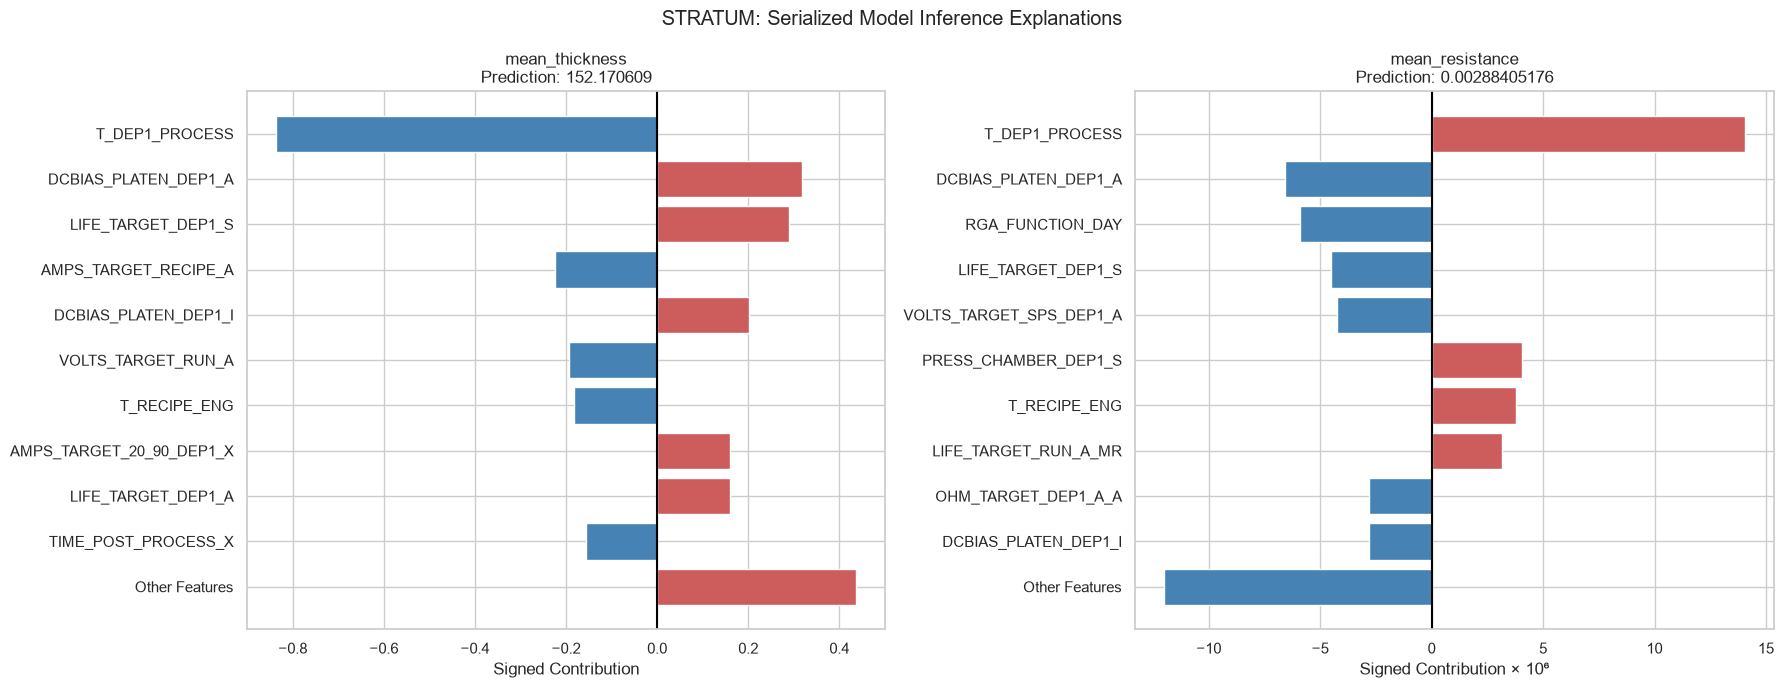

In [20]:

# Visualise signed local feature contributions

fig, axes = plt.subplots(
    1, 2, figsize=(18, 7)
)

for ax, target in zip(axes, TARGETS):

    evidence = explanation_response[
        "explanations"
    ][target]

    plot_data = pd.DataFrame(
        evidence["top_features"]
    )[["feature", "contribution"]]

    plot_data = pd.concat([
        plot_data,

        pd.DataFrame([{
            "feature": "Other Features",

            "contribution": evidence[
                "other_feature_contribution"
            ],
        }]),
    ], ignore_index=True)

    multiplier = (
        1_000_000

        if target == "mean_resistance"

        else 1
    )

    colors = [
        "indianred" if value > 0 else "steelblue"

        for value in plot_data["contribution"]
    ]

    ax.barh(
        plot_data["feature"],

        plot_data["contribution"] * multiplier,

        color=colors,
    )

    ax.invert_yaxis()

    ax.axvline(
        0,
        color="black",
    )

    ax.set_title(
        f"{target}\n"
        f"Prediction: {evidence['prediction']:.9g}"
    )

    ax.set_xlabel(
        "Signed Contribution × 10⁶"

        if target == "mean_resistance"

        else "Signed Contribution"
    )

plt.suptitle(
    "STRATUM: Serialized Model Inference Explanations"
)

plt.tight_layout()
plt.show()

## 12. Inference Input Robustness

Investigate ordinary, missing-measurement,
unknown-equipment and malformed-input
scenarios.

Verify that valid inputs produce
finite positive predictions.

Verify that malformed inputs raise
explicit validation errors.

Synthetic scenarios assess software
behaviour, not predictive accuracy under
unseen manufacturing conditions.

In [21]:

# Construct inference validation scenarios

missing_sensor_record = sample_record.copy()

observed_features = [
    feature

    for feature in apc_features

    if sample_record[feature] is not None
]

assert len(observed_features) >= 5

for feature in observed_features[:5]:

    missing_sensor_record[feature] = None

unknown_equipment_record = {
    **sample_record,

    "equipment": "synthetic_unknown_equipment",
}

missing_equipment_record = {
    **sample_record,

    "equipment": None,
}

extreme_sensor_record = sample_record.copy()

extreme_feature = next(
    feature

    for feature, stats in
    warning_profile["feature_statistics"].items()

    if stats["mean"] is not None

    and stats["std"] is not None

    and stats["std"] > 0
)

stats = warning_profile[
    "feature_statistics"
][extreme_feature]

extreme_sensor_record[extreme_feature] = (
    stats["mean"] + 10 * stats["std"]
)

elevated_missingness_record = sample_record.copy()

for feature in apc_features:

    if feature != observed_features[0]:

        elevated_missingness_record[feature] = None

missing_column_record = sample_record.copy()

del missing_column_record[apc_features[0]]

invalid_numeric_record = {
    **sample_record,

    apc_features[0]: "invalid_sensor_value",
}

numeric_string_record = {
    **sample_record,

    apc_features[0]: "123.45",
}

boolean_record = {
    **sample_record,

    apc_features[0]: True,
}

infinity_record = {
    **sample_record,

    apc_features[0]: float("inf"),
}

all_missing_record = {
    **{
        feature: None

        for feature in apc_features
    },

    "equipment": sample_record["equipment"],
}

unexpected_target_record = {
    **sample_record,

    "mean_thickness": 150.0,
}

scenarios = [
    ("Ordinary Input", sample_record, True),

    (
        "Additional Missing Sensors",
        missing_sensor_record,
        True,
    ),

    (
        "Unknown Equipment",
        unknown_equipment_record,
        True,
    ),

    (
        "Missing Equipment",
        missing_equipment_record,
        True,
    ),

    (
        "Extreme Sensor",
        extreme_sensor_record,
        True,
    ),

    (
        "Elevated Missingness",
        elevated_missingness_record,
        True,
    ),

    (
        "Missing Required Column",
        missing_column_record,
        False,
    ),

    (
        "Invalid Numeric Value",
        invalid_numeric_record,
        False,
    ),

    (
        "Numeric String",
        numeric_string_record,
        False,
    ),

    (
        "Boolean Sensor Value",
        boolean_record,
        False,
    ),

    (
        "Infinite Sensor Value",
        infinity_record,
        False,
    ),

    (
        "All APC Measurements Missing",
        all_missing_record,
        False,
    ),

    (
        "Unexpected Measured Target",
        unexpected_target_record,
        False,
    ),
]

print("Prepared robustness scenarios:", len(scenarios))

Prepared robustness scenarios: 13


In [22]:

# Execute inference input validation experiments

robustness_rows = []

required_warning_codes = {
    "Unknown Equipment": "UNKNOWN_EQUIPMENT",

    "Missing Equipment": "MISSING_EQUIPMENT",

    "Extreme Sensor": "EXTREME_SENSOR_VALUES",

    "Elevated Missingness": "ELEVATED_MISSINGNESS",
}

for name, record, should_accept in scenarios:

    try:

        response = engine.predict_one(
            record
        )

        if not should_accept:

            raise AssertionError(
                f"Invalid input was accepted: {name}"
            )

        result = response["records"][0]

        predictions = result["predictions"]

        assert all(
            np.isfinite(value) and value > 0

            for value in predictions.values()
        )

        codes = result["warnings"]["codes"]

        if name in required_warning_codes:

            assert required_warning_codes[name] in codes

        json.dumps(
            response,

            allow_nan=False,
        )

        robustness_rows.append({
            "Scenario": name,

            "Expected": "Accept",

            "Actual": "Accept",

            "Warnings": ", ".join(codes),

            "Error": None,

            "Passed": True,
        })

    except InputValidationError as error:

        if should_accept:

            raise

        robustness_rows.append({
            "Scenario": name,

            "Expected": "Reject",

            "Actual": "Reject",

            "Warnings": None,

            "Error": str(error),

            "Passed": True,
        })

robustness_summary = pd.DataFrame(
    robustness_rows
)

display(robustness_summary)

assert len(robustness_summary) == 13

assert robustness_summary["Passed"].all()

print("\nAll 13 robustness scenarios: PASSED")

,Scenario,Expected,Actual,Warnings,Error,Passed
0,Ordinary Input,Accept,Accept,"ELEVATED_MISSINGNESS, EXTREME_SENSOR_VALUES",NaN,True
1,Additional Missing Sensors,Accept,Accept,"ELEVATED_MISSINGNESS, EXTREME_SENSOR_VALUES",NaN,True
2,Unknown Equipment,Accept,Accept,"ELEVATED_MISSINGNESS, EXTREME_SENSOR_VALUES, U...",NaN,True
3,Missing Equipment,Accept,Accept,"ELEVATED_MISSINGNESS, EXTREME_SENSOR_VALUES, M...",NaN,True
4,Extreme Sensor,Accept,Accept,"ELEVATED_MISSINGNESS, EXTREME_SENSOR_VALUES",NaN,True
5,Elevated Missingness,Accept,Accept,ELEVATED_MISSINGNESS,NaN,True
6,Missing Required Column,Reject,Reject,NaN,Missing required columns: ['AMPS_TARGET_20_90_...,True
7,Invalid Numeric Value,Reject,Reject,NaN,Non-numeric value in AMPS_TARGET_20_90_DELTA_D...,True
8,Numeric String,Reject,Reject,NaN,Non-numeric value in AMPS_TARGET_20_90_DELTA_D...,True
9,Boolean Sensor Value,Reject,Reject,NaN,"Boolean value in AMPS_TARGET_20_90_DELTA_DEP1,...",True



All 13 robustness scenarios: PASSED


In [23]:

# Verify explanation robustness

explanation_scenarios = [
    ("Ordinary Input", sample_record),

    (
        "Additional Missing Sensors",
        missing_sensor_record,
    ),

    (
        "Unknown Equipment",
        unknown_equipment_record,
    ),

    (
        "Missing Equipment",
        missing_equipment_record,
    ),
]

explanation_robustness_rows = []

for name, record in explanation_scenarios:

    result = engine.explain_one(
        record,
        top_n=10,
    )

    json.dumps(
        result,
        allow_nan=False,
    )

    for target in TARGETS:

        evidence = result[
            "explanations"
        ][target]

        reconstructed = (
            evidence["base_prediction"]

            + sum(
                item["contribution"]

                for item in evidence["top_features"]
            )

            + evidence["other_feature_contribution"]
        )

        np.testing.assert_allclose(
            reconstructed,

            evidence["prediction"],

            rtol=1e-5,

            atol=1e-10,
        )

        explanation_robustness_rows.append({
            "Scenario": name,

            "Target": target,

            "Prediction": evidence["prediction"],

            "Reconstruction Error": abs(
                reconstructed
                - evidence["prediction"]
            ),

            "Passed": True,
        })

explanation_robustness_summary = pd.DataFrame(
    explanation_robustness_rows
)

display(explanation_robustness_summary)

assert len(explanation_robustness_summary) == 8

assert explanation_robustness_summary[
    "Passed"
].all()

print("Explanation robustness: PASSED")


,Scenario,Target,Prediction,Reconstruction Error,Passed
0,Ordinary Input,mean_thickness,152.170609,2.424961e-04,True
1,Ordinary Input,mean_resistance,0.002884,6.866900e-11,True
2,Additional Missing Sensors,mean_thickness,151.443069,2.344603e-04,True
3,Additional Missing Sensors,mean_resistance,0.002890,2.026525e-10,True
4,Unknown Equipment,mean_thickness,152.170609,2.424961e-04,True
5,Unknown Equipment,mean_resistance,0.002883,1.964556e-10,True
6,Missing Equipment,mean_thickness,152.170609,2.424961e-04,True
7,Missing Equipment,mean_resistance,0.002883,4.557448e-11,True


Explanation robustness: PASSED


## 13. Automated Test Fixture

Preserve a minimal historical process
input example from the eligible
development population.

Exclude wafer identifiers, measured
material-property targets and quality
labels.

Use the fixture to support reproducible
inference and application integration tests.

The fixture is not an independent
predictive evaluation dataset.

In [24]:

# Create a locally generated inference fixture

fixture_path = (
    artifact_root / "inference_fixture.json"
)

inference_fixture = {
    "project": "STRATUM",

    "model_version": MODEL_VERSION,

    "source_population": (
        "eligible_combined_development"
    ),

    "inputs": sample_record,

    "expected_predictions": single_response[
        "records"
    ][0]["predictions"],
}

write_json(
    fixture_path,
    inference_fixture,
)

assert read_json(fixture_path) == inference_fixture

print("Inference fixture created.")

print(fixture_path)

Inference fixture created.
c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\ml\artifacts\inference_fixture.json


In [27]:
%pip install pytest

  Using cached pytest-9.2.0-py3-none-any.whl.metadata (7.9 kB)
  Using cached iniconfig-2.3.1-py3-none-any.whl.metadata (2.8 kB)
  Using cached pluggy-1.7.0-py3-none-any.whl.metadata (5.0 kB)
Using cached pytest-9.2.0-py3-none-any.whl (411 kB)
Using cached pluggy-1.7.0-py3-none-any.whl (27 kB)
Using cached iniconfig-2.3.1-py3-none-any.whl (7.6 kB)

   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   -------------------------- ------------- 2/3 [pytest]
   ---------------------------------------- 3/3 [pytest]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
import pytest

print("Pytest version:", pytest.__version__)
print("Pytest installation: VERIFIED")

Pytest version: 9.2.0
Pytest installation: VERIFIED


In [28]:

# Execute the automated inference integration tests

test_run = subprocess.run(
    [
        sys.executable,

        "-m",

        "pytest",

        "tests/test_inference.py",

        "-v",

        "--tb=short",
    ],

    cwd=project_root,

    capture_output=True,

    text=True,

    encoding="utf-8",

    errors="replace",
)

print(test_run.stdout)

if test_run.stderr:

    print(test_run.stderr)

assert test_run.returncode == 0, (
    "Automated inference tests failed."
)

print("\nAutomated inference tests: PASSED")

============================= test session starts =============================
platform win32 -- Python 3.14.3, pytest-9.2.0, pluggy-1.7.0 -- c:\Users\Tarun Raja\OneDrive\Documents\STRATUM\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: c:\Users\Tarun Raja\OneDrive\Documents\STRATUM
plugins: platformdirs-4.13.5
collecting ... collected 22 items

tests/test_inference.py::test_model_bundle_integrity PASSED              [  4%]
tests/test_inference.py::test_inference_schema PASSED                    [  9%]
tests/test_inference.py::test_single_record_prediction PASSED            [ 13%]
tests/test_inference.py::test_batch_prediction_order PASSED              [ 18%]
tests/test_inference.py::test_feature_column_order_independent PASSED    [ 22%]
tests/test_inference.py::test_missing_sensor_measurement PASSED          [ 27%]
tests/test_inference.py::test_missing_required_column PASSED             [ 31%]
tests/test_inference.py::test_invalid_sensor_values[invalid] PASSED      [ 36%]
t

## 14. End-to-End Inference Engine Benchmark

Measure complete dual-target inference
latency for single-record and batch
prediction scenarios.

Include input validation, preprocessing,
both fitted-model predictions, input
distribution warnings and response
construction.

Measure local explanation generation
separately.

Exclude network, database, frontend
and LLM overhead.

In [29]:

# Benchmark application-facing inference functions

def benchmark_function(
    function,
    repetitions=20,
    warmup=3,
):

    for _ in range(warmup):

        function()

    timings = []

    for _ in range(repetitions):

        start = time.perf_counter()

        result = function()

        json.dumps(
            result,
            allow_nan=False,
        )

        timings.append(
            (time.perf_counter() - start) * 1000
        )

    return {
        "Repetitions": repetitions,

        "Median Latency (ms)": float(
            np.median(timings)
        ),

        "P95 Latency (ms)": float(
            np.quantile(timings, 0.95)
        ),

        "Minimum Latency (ms)": float(
            np.min(timings)
        ),
    }


benchmark_inputs = development_df[
    engine.required_columns
].iloc[:256].copy()

benchmark_scenarios = [
    (
        "Single-record dual prediction",

        1,

        lambda: engine.predict_one(
            sample_record
        ),
    ),

    (
        "32-record dual prediction",

        32,

        lambda: engine.predict_batch(
            benchmark_inputs.iloc[:32]
        ),
    ),

    (
        "256-record dual prediction",

        256,

        lambda: engine.predict_batch(
            benchmark_inputs
        ),
    ),

    (
        "Single-record dual explanation",

        1,

        lambda: engine.explain_one(
            sample_record
        ),
    ),
]

engine_benchmark_rows = []

for name, records, function in benchmark_scenarios:

    print("Benchmarking:", name, flush=True)

    engine_benchmark_rows.append({
        "Scenario": name,

        "Records": records,

        **benchmark_function(function),
    })

engine_benchmark_summary = pd.DataFrame(
    engine_benchmark_rows
)

display(
    engine_benchmark_summary.round(6)
)

Benchmarking: Single-record dual prediction
Benchmarking: 32-record dual prediction
Benchmarking: 256-record dual prediction
Benchmarking: Single-record dual explanation


,Scenario,Records,Repetitions,Median Latency (ms),P95 Latency (ms),Minimum Latency (ms)
0,Single-record dual prediction,1,20,65.64880,88.180490,59.8734
1,32-record dual prediction,32,20,81.42345,89.587815,73.0441
2,256-record dual prediction,256,20,174.75615,201.193770,159.4214
3,Single-record dual explanation,1,20,147.49130,195.603215,130.6645


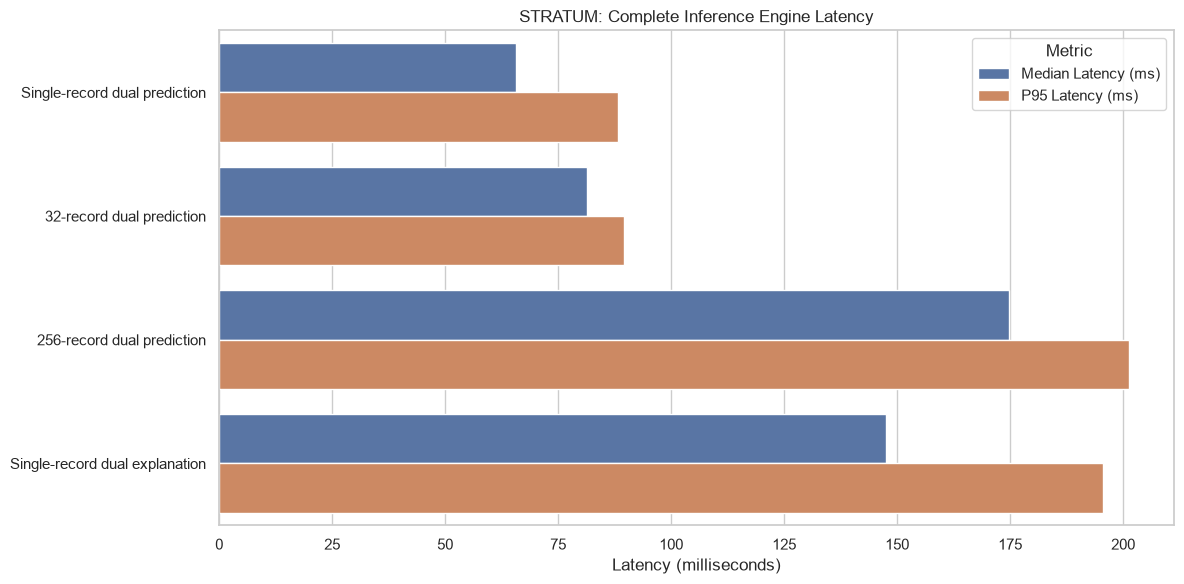

In [30]:

# Visualise complete inference engine latency

plot_data = engine_benchmark_summary.melt(
    id_vars=["Scenario"],

    value_vars=[
        "Median Latency (ms)",

        "P95 Latency (ms)",
    ],

    var_name="Metric",

    value_name="Latency (ms)",
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_data,

    x="Latency (ms)",

    y="Scenario",

    hue="Metric",
)

plt.title(
    "STRATUM: Complete Inference Engine Latency"
)

plt.xlabel("Latency (milliseconds)")

plt.ylabel("")

plt.tight_layout()
plt.show()

## 15. Independent Process Verification

Start a fresh Python process.

Load only the serialized model bundle
and a process-input fixture.

Generate dual-target predictions and
verify agreement with the previously
recorded fixture predictions.

Do not load the original dataset or
invoke model-training routines.

In [31]:

# Verify independent Python process inference

smoke_script = """
import json
from pathlib import Path
import numpy as np

from ml.inference import StratumInferenceEngine

root = Path("ml") / "artifacts"

fixture = json.loads(
    (root / "inference_fixture.json").read_text(
        encoding="utf-8"
    )
)

engine = StratumInferenceEngine(
    root / fixture["model_version"]
)

response = engine.predict_one(
    fixture["inputs"]
)

predictions = response["records"][0]["predictions"]

for target, expected in fixture[
    "expected_predictions"
].items():

    np.testing.assert_allclose(
        predictions[target],
        expected,
        rtol=1e-10,
        atol=1e-15,
    )

print(
    json.dumps(
        response,
        allow_nan=False,
    )
)

print("INDEPENDENT_PROCESS_PASSED")
"""

smoke_run = subprocess.run(
    [
        sys.executable,

        "-c",

        smoke_script,
    ],

    cwd=project_root,

    capture_output=True,

    text=True,

    encoding="utf-8",

    errors="replace",
)

print(smoke_run.stdout)

if smoke_run.stderr:

    print(smoke_run.stderr)

assert smoke_run.returncode == 0

assert "INDEPENDENT_PROCESS_PASSED" in (
    smoke_run.stdout
)

print("\nIndependent inference process: VERIFIED")

{"model_version": "1.0.0", "record_count": 1, "output_scale": "dataset_units", "records": [{"row_index": 0, "equipment": "equipment_13", "predictions": {"mean_thickness": 152.1706085205078, "mean_resistance": 0.002884051762521267}, "warnings": {"has_warning": true, "codes": ["ELEVATED_MISSINGNESS", "EXTREME_SENSOR_VALUES"], "missing_apc_inputs": 36, "extreme_apc_inputs": 1, "constant_feature_deviations": 0, "previously_unobserved_features": 0, "calibrated_uncertainty": false}}], "interpretation": "Virtual metrology estimates for engineering review; not wafer acceptance decisions."}
INDEPENDENT_PROCESS_PASSED


Independent inference process: VERIFIED



## 16. Application Integration Contract

The backend loads a trusted model bundle
using StratumInferenceEngine.

### Startup

Instantiate the inference engine once
during application startup.

Verify artifact checksums, runtime
compatibility and model input schemas.

If artifact loading fails, report
application readiness failure rather
than serving fabricated predictions.

### Prediction Operations

predict_one(inputs):

Accepts a dictionary containing all
110 APC features and equipment.

predict_batch(inputs):

Accepts a pandas DataFrame containing
the required inference columns.

explain_one(inputs, top_n=10):

Generates original-scale predictions
and local TreeSHAP evidence.

get_model_information():

Returns model metadata, final held-out
performance and updated global
explainability results.

### Validation

InputValidationError:

Represents invalid input schemas or
malformed measurement values.

PredictionError:

Represents non-finite, non-positive
or otherwise invalid model outputs.

### Backend Responsibilities

- Authentication and authorization.
- CSV parsing and request validation.
- Upload size and record limits.
- Separation of identifiers, measured
  properties and predictive inputs.
- Prediction persistence.
- Measured-metrology reconciliation.
- Structured API error responses.
- Request logging.
- On-demand explanation requests.
- Grounded LLM integration.

### Interpretation

Predictions are returned in the
original dataset target scale.

Physical engineering units remain
unverified.

Input distribution warnings do not
represent calibrated confidence.

Measured quality labels and predictions
must remain distinct.

No wafer acceptance decision is
generated by the inference engine.

In [32]:

# Verify model analytics information

model_information = engine.get_model_information()

assert model_information[
    "model_version"
] == MODEL_VERSION

assert len(
    model_information["final_performance"]
) == 2

assert model_information[
    "global_explainability"
]["records"] == 4165

json.dumps(
    model_information,
    allow_nan=False,
)

display(
    pd.DataFrame(
        model_information["final_performance"]
    )
)

print("Frontend model information: VERIFIED")

print(
    "Global explanation population:",

    model_information[
        "global_explainability"
    ]["explanation_population"],
)

,Target,Candidate,Reference Baseline,Baseline MAE,Final Test MAE,Final Test RMSE,Final Test R2,Final Test MAPE (%),Final Test Bias,MAE Improvement (%),Non-Positive Predictions
0,mean_thickness,XGB-4,Equipment Mean,1.960417,1.193555,1.555422,0.583907,0.786179,-0.034797,39.117303,0
1,mean_resistance,RES-XGB-2,Global Mean,0.000040,0.000024,0.000032,0.570150,0.836203,0.000007,39.583959,0


Frontend model information: VERIFIED
Global explanation population: eligible_combined_development


## 17. Final ML Integrity Verification

Verify model version consistency,
dataset provenance, population
fingerprints, numerical reproduction,
serialization fidelity, batch inference,
warning reproduction, explanation
additivity and automated test outcomes.

Confirm that all required model bundle
artifacts are present and unchanged.

The resulting model bundle is ready
for academic application integration
subject to documented limitations.

In [33]:

# Consolidated ML integrity verification

verified_manifest = verify_bundle(
    bundle_path
)

assert verified_manifest == artifact_manifest

assert reproduction_summary["Passed"].all()

assert roundtrip_summary[
    "Exact Prediction Match"
].all()

assert batch_verification[
    "Exact Prediction Match"
].all()

assert warning_reproduction["Passed"].all()

assert robustness_summary["Passed"].all()

assert explanation_robustness_summary[
    "Passed"
].all()

assert artifact_summary["Verified"].all()

assert test_run.returncode == 0

assert smoke_run.returncode == 0

assert len(global_importance_tables) == 2

assert len(
    global_importance_tables["mean_thickness"]
) == 110

assert len(
    global_importance_tables["mean_resistance"]
) == 111

assert evaluation["model_configurations"] == (
    model_configs
)

assert not protocol[
    "further_hyperparameter_selection"
]

assert not protocol[
    "test_based_model_replacement"
]

for target in TARGETS:

    assert np.isfinite(
        reconstructed_test_predictions[target]
    ).all()

print("Dataset provenance: VERIFIED")

print("Frozen configurations: VERIFIED")

print("Metric reproduction: VERIFIED")

print("Serialization round-trip: VERIFIED")

print("Artifact integrity: VERIFIED")

print("Dual-target inference: VERIFIED")

print("Input warning reproduction: VERIFIED")

print("Input validation: VERIFIED")

print("Final-model explainability: VERIFIED")

print("Automated tests: PASSED")

print("Independent inference process: PASSED")

print("\nSTRATUM ML IMPLEMENTATION: COMPLETE")

Dataset provenance: VERIFIED
Frozen configurations: VERIFIED
Metric reproduction: VERIFIED
Serialization round-trip: VERIFIED
Artifact integrity: VERIFIED
Dual-target inference: VERIFIED
Input warning reproduction: VERIFIED
Input validation: VERIFIED
Final-model explainability: VERIFIED
Automated tests: PASSED
Independent inference process: PASSED

STRATUM ML IMPLEMENTATION: COMPLETE


## 18. Model Serialization Result Preservation

Preserve numerical reproduction evidence,
artifact checksums, inference validation,
explanation reconstruction and complete
inference latency benchmarks.

Store deployment-oriented research evidence
separately from locally generated binary
model artifacts.

The saved results provide a traceable
connection between evaluated models and
the forthcoming application implementation.

In [38]:

# Export final model serialization research evidence

def json_records(frame):

    return (
        frame.astype(object)

        .where(
            pd.notna(frame),
            None,
        )

        .to_dict(orient="records")
    )


import re

clean_test_output = re.sub(
    r"\x1b\[[0-9;]*m",
    "",
    test_run.stdout,
)

test_summary_lines = [
    line.strip()
    for line in clean_test_output.splitlines()
    if " passed" in line
]

serialization_results = {
    "project": "STRATUM",

    "experiment": "model_serialization_and_inference",

    "model_version": MODEL_VERSION,

    "dataset_sha256": evaluation[
        "dataset_sha256"
    ],

    "partition_summary": partition,

    "model_configurations": model_configs,

    "runtime_versions": runtime_versions(),

    "model_n_jobs": MODEL_N_JOBS,

    "random_state": RANDOM_STATE,

    "artifact_manifest": artifact_manifest,

    "artifact_summary": json_records(
        artifact_summary
    ),

    "bundle_size_bytes": sum(
        path.stat().st_size

        for path in bundle_path.iterdir()

        if path.is_file()
    ),

    "fitting_summary": json_records(
        fitting_summary
    ),

    "metric_reproduction": json_records(
        reproduction_summary
    ),

    "serialization_roundtrip": json_records(
        roundtrip_summary
    ),

    "batch_inference_verification": json_records(
        batch_verification
    ),

    "warning_reproduction": json_records(
        warning_reproduction
    ),

    "robustness_summary": json_records(
        robustness_summary
    ),

    "local_explanation_verification": json_records(
        local_explanation_summary
    ),

    "explanation_robustness": json_records(
        explanation_robustness_summary
    ),

    "global_explainability": global_explainability,

    "engine_loading_seconds": engine_load_seconds,

    "engine_benchmarks": json_records(
        engine_benchmark_summary
    ),

    "automated_tests": {
        "return_code": test_run.returncode,

        "passed": test_run.returncode == 0,

        "summary_lines": test_summary_lines,
    },

    "independent_process_verification": (
        smoke_run.returncode == 0
    ),

    "test_based_model_selection": False,

    "calibrated_prediction_uncertainty": False,

    "binary_artifacts_committed_to_git": False,

    "limitations": [
        "Joblib bundles must originate from trusted sources.",

        "Checksums detect changes but do not authenticate origin.",

        "Exact compatible dependency versions are required.",

        "Synthetic robustness tests establish software "
        "behaviour rather than predictive accuracy.",

        "Final global explanations describe model behaviour "
        "on eligible development observations.",

        "Inference benchmarks exclude application-level overhead.",

        "No external industrial validation was performed.",
    ],
}

serialization_results_path = (
    results_dir / "model_serialization.json"
)

write_json(
    serialization_results_path,

    serialization_results,
)

# Preserve the portable input schema for Codex
# without including any raw process observations.

write_json(
    results_dir / "inference_schema.json",

    input_schema,
)

print("Serialization results preserved.")

print("ml/results/model_serialization.json")

print("ml/results/inference_schema.json")

Serialization results preserved.
ml/results/model_serialization.json
ml/results/inference_schema.json


In [35]:

# Verify preserved serialization research artifacts

saved_serialization = read_json(
    serialization_results_path
)

saved_schema = read_json(
    results_dir / "inference_schema.json"
)

assert saved_serialization[
    "model_version"
] == MODEL_VERSION

assert saved_serialization[
    "artifact_manifest"
] == artifact_manifest

assert saved_serialization[
    "dataset_sha256"
] == evaluation["dataset_sha256"]

assert saved_serialization[
    "partition_summary"
] == partition

assert saved_serialization[
    "automated_tests"
]["passed"]

assert saved_serialization[
    "independent_process_verification"
]

assert saved_schema == input_schema

assert len(
    saved_schema["apc_features"]
) == 110

print("Serialization result JSON: VERIFIED")

print("Portable inference schema JSON: VERIFIED")

print("\nAll final ML research artifacts verified.")

Serialization result JSON: VERIFIED
Portable inference schema JSON: VERIFIED

All final ML research artifacts verified.


In [36]:

# Consolidated STRATUM ML implementation summary

print("=" * 75)

print("STRATUM - MODEL SERIALIZATION AND INFERENCE")

print("=" * 75)

print("\nMODEL BUNDLE")

print("Version:", MODEL_VERSION)

print("Development records:", len(development_df))

print("Final test records:", len(test_df))

print("\nMODEL REPRODUCTION")

display(reproduction_summary.round(12))

print("\nARTIFACT SUMMARY")

display(
    artifact_summary[
        ["Artifact", "Bytes", "Size (KiB)", "Verified"]
    ]
)

print("\nSERIALIZATION ROUND-TRIP")

display(roundtrip_summary)

print("\nBATCH INFERENCE VERIFICATION")

display(batch_verification)

print("\nWARNING REPRODUCTION")

display(warning_reproduction)

print("\nFINAL GLOBAL EXPLAINABILITY")

print(
    json.dumps(
        global_explainability[
            "cross_target_comparison"
        ],

        indent=4,
    )
)

for target in TARGETS:

    print("\nTarget:", target)

    display(
        global_importance_tables[target].head(10)
    )

print("\nINPUT ROBUSTNESS")

display(robustness_summary)

print("\nEXPLANATION ROBUSTNESS")

display(explanation_robustness_summary)

print("\nINFERENCE BENCHMARKS")

display(engine_benchmark_summary.round(6))

print("\nAUTOMATED TEST RESULTS")

for line in test_summary_lines:

    print(line)

print("\nINDEPENDENT INFERENCE PROCESS: PASSED")

print("\nMODEL SERIALIZATION: COMPLETE")

print("INFERENCE ENGINE: COMPLETE")

print("ML RESEARCH PHASE: COMPLETE")

print("APPLICATION DEVELOPMENT: NEXT")

print("=" * 75)

STRATUM - MODEL SERIALIZATION AND INFERENCE

MODEL BUNDLE
Version: 1.0.0
Development records: 4165
Final test records: 1042

MODEL REPRODUCTION


,Target,Candidate,MAE,RMSE,R2,MAPE (%),Bias,Reference MAE,MAE Difference,Reference R2,R2 Difference,Passed
0,mean_thickness,XGB-4,1.193555,1.555422,0.583907,0.786179,-0.034797,1.193555,0.0,0.583907,0.0,True
1,mean_resistance,RES-XGB-2,0.000024,0.000032,0.570150,0.836203,0.000007,0.000024,0.0,0.570150,0.0,True



ARTIFACT SUMMARY


,Artifact,Bytes,Size (KiB),Verified
0,evaluation.json,140794,137.494141,True
1,global_explainability.json,69878,68.240234,True
2,input_schema.json,36107,35.260742,True
3,input_warning_profile.json,24096,23.531250,True
4,metadata.json,5213,5.090820,True
5,resistance.joblib,339373,331.418945,True
6,thickness.joblib,333304,325.492188,True



SERIALIZATION ROUND-TRIP


,Target,Verified Predictions,Maximum Prediction Difference,Exact Prediction Match
0,mean_thickness,1042,0.0,True
1,mean_resistance,1042,0.0,True


... (11 outputs left out)

,Scenario,Target,Prediction,Reconstruction Error,Passed
0,Ordinary Input,mean_thickness,152.170609,2.424961e-04,True
1,Ordinary Input,mean_resistance,0.002884,6.866900e-11,True
2,Additional Missing Sensors,mean_thickness,151.443069,2.344603e-04,True
3,Additional Missing Sensors,mean_resistance,0.002890,2.026525e-10,True
4,Unknown Equipment,mean_thickness,152.170609,2.424961e-04,True
5,Unknown Equipment,mean_resistance,0.002883,1.964556e-10,True
6,Missing Equipment,mean_thickness,152.170609,2.424961e-04,True
7,Missing Equipment,mean_resistance,0.002883,4.557448e-11,True



INFERENCE BENCHMARKS


,Scenario,Records,Repetitions,Median Latency (ms),P95 Latency (ms),Minimum Latency (ms)
0,Single-record dual prediction,1,20,65.64880,88.180490,59.8734
1,32-record dual prediction,32,20,81.42345,89.587815,73.0441
2,256-record dual prediction,256,20,174.75615,201.193770,159.4214
3,Single-record dual explanation,1,20,147.49130,195.603215,130.6645



AUTOMATED TEST RESULTS
============================= 22 passed in 5.54s ==============================

INDEPENDENT INFERENCE PROCESS: PASSED

MODEL SERIALIZATION: COMPLETE
INFERENCE ENGINE: COMPLETE
ML RESEARCH PHASE: COMPLETE
APPLICATION DEVELOPMENT: NEXT



## 19. Findings and Application Integration

### Objective

Prepare the evaluated STRATUM virtual
metrology models for reproducible
software application integration.

Preserve complete fitted pipelines,
preprocessing, feature schemas, target
transformations and research evidence.

### Model Reconstruction

Both frozen configurations were
reconstructed using the eligible
development population of 4165 records.

The reserved chronological test
population contained 1042 records.

Dataset fingerprints and ordered
population fingerprints were verified.

Thickness configuration:

- Candidate: XGB-4.
- Raw features: 110.
- Transformed features: 157.
- Boosting rounds: 820.
- Equipment metadata: Excluded.
- Reconstruction training time:
  4.086394 seconds.

Resistance configuration:

- Candidate: RES-XGB-2.
- Raw features: 111.
- Transformed features: 173.
- Boosting rounds: 837.
- Equipment metadata: Included.
- Target transformation: StandardScaler.
- Reconstruction training time:
  4.218400 seconds.

The original random state of 42
and thread configuration of n_jobs=-1
were preserved.

The resistance target scaler retained
the following fitted parameters:

- Mean: 0.002897853372709674.
- Scale: 5.352031605994806e-05.

No additional model selection or
test-based optimisation was performed.

### Final Metric Reproduction

Thickness reconstructed metrics:

- MAE: 1.1935546087907907.
- RMSE: 1.5554220973663535.
- R2: 0.5839070531214829.
- MAPE: 0.7861786268677532%.
- Bias: -0.03479677441917672.

Resistance reconstructed metrics:

- MAE: 2.4237906652058367e-05.
- RMSE: 3.2328871924355e-05.
- R2: 0.5701504703401694.
- MAPE: 0.8362032646051081%.
- Bias: 6.615650541186738e-06.

Both reconstructed models reproduced
the recorded final evaluation metrics.

For both material properties:

- MAE reproduction difference: 0.0.
- R2 reproduction difference: 0.0.

All metric reproduction assertions passed.

The results establish agreement with
saved aggregate evaluation evidence.

Aggregate metric reproduction does not
independently prove identical fitted
tree structures.

### Versioned Model Serialization

The initial model bundle version
is 1.0.0.

The complete fitted pipelines were
serialized using compressed joblib
serialization.

The bundle contains:

- thickness.joblib
- resistance.joblib
- metadata.json
- input_schema.json
- input_warning_profile.json
- global_explainability.json
- evaluation.json
- manifest.json

Artifact sizes:

Thickness pipeline:

- Bytes: 333304.
- Approximate size: 325.49 KiB.

Resistance pipeline:

- Bytes: 339373.
- Approximate size: 331.42 KiB.

Combined compressed fitted models:

- Bytes: 672677.
- Approximate size: 656.91 KiB.

Complete model bundle:

- Bytes: 949583.
- Approximate size: 927.33 KiB.

The complete bundle occupies less
than one MiB of serialized disk storage.

All seven manifest-listed artifacts
passed SHA256 checksum verification.

Existing model versions cannot be
silently overwritten.

The registry verifies compatible
runtime dependency versions.

Checksum verification detects artifact
modifications but does not authenticate
the origin of a model bundle.

Pickle-based artifacts must originate
from trusted sources.

### Serialization Round-Trip Verification

Both fitted models were restored from
the permanent joblib artifacts.

For each material property:

- Verified predictions: 1042.
- Maximum prediction difference: 0.0.
- Exact prediction agreement: True.

A total of 2084 material-property
predictions were compared.

Fitted feature ordering, transformed
feature dimensions, boosting rounds
and resistance scaler parameters
were verified after loading.

Permanent serialization did not alter
the evaluated predictions.

### Final-Model Global Explainability

Native XGBoost TreeSHAP contributions
were recomputed using the final fitted
models.

Explanation population:

- Eligible combined development.
- Observations: 4165.

Thickness explanation dimensions:

- Transformed features: 157.
- Raw input groups: 110.

Resistance explanation dimensions:

- Transformed features: 173.
- Raw input groups: 111.

Maximum reconstruction errors:

- Thickness: 4.8461100414e-04.
- Resistance: 3.4130721166e-10.

All established reconstruction checks
passed.

Leading thickness predictors:

1. T_DEP1_PROCESS: 13.032520%.
2. T_RECIPE_ENG: 10.860595%.
3. LIFE_TARGET_DEP1_S: 5.191068%.
4. LIFE_TARGET_DEP1_A: 4.618770%.
5. VOLTS_TARGET_RUN_A: 4.224166%.

Leading resistance predictors:

1. T_DEP1_PROCESS: 12.476551%.
2. T_RECIPE_ENG: 9.829552%.
3. LIFE_TARGET_DEP1_S: 4.072595%.
4. VOLTS_TARGET_SPS_DEP1_A: 3.487947%.
5. VOLTS_TARGET_RE_A: 3.052635%.

The three leading predictors were
identical across both fitted models.

Importance percentages represent
normalised mean absolute grouped
TreeSHAP contributions.

Cross-target APC predictor comparison:

- Shared APC inputs: 110.
- Spearman rank correlation:
  0.8924599328269053.
- Shared top-10 predictors: 8.

Shared leading APC predictors:

- AMPS_TARGET_20_90_DEP1_SPS_X.
- DCBIAS_PLATEN_DEP1_A.
- LIFE_TARGET_DEP1_A.
- LIFE_TARGET_DEP1_S.
- T_DEP1_PROCESS.
- T_RECIPE_ENG.
- VOLTS_TARGET_RE_A.
- VOLTS_TARGET_RUN_A.

These findings demonstrate substantial
agreement in fitted model attribution
rankings.

They complement earlier development-stage
explainability investigations.

The current explanation population
consists of development observations,
rather than independent held-out data.

Feature contributions do not establish
physical causality.

### Inference Input Contract

The combined inference workflow
requires 111 input columns:

- 110 APC process variables.
- One equipment metadata field.

Individual missing measurements are
permitted.

Missing required columns are rejected.

Invalid numeric values, numeric strings,
boolean inputs, infinite values and
duplicate columns are rejected.

Unexpected measured targets and quality
labels are not accepted as predictive
inputs.

Unknown or missing equipment produces
explicit warning codes.

An observation containing no APC
measurements is rejected.

The combined input schema is preserved
in inference_schema.json.

### Dual-Target Inference Engine

The reusable inference implementation
provides:

- Single-record prediction.
- Batch prediction.
- Input validation.
- Distribution warning generation.
- Local TreeSHAP explanations.
- Model analytics metadata.

Both predictions are returned in
their original dataset target scales.

The complete inference engine was
verified using 1042 reserved test
observations.

For each target:

- Maximum prediction difference: 0.0.
- Exact agreement with direct fitted
  model predictions: True.

Input ordering and output record
alignment were preserved.

All batch inference checks passed.

### Input Warning Reproduction

The deployed inference interface
uses the final development-fitted
input warning profile.

Final test warning counts:

- Extreme sensor warnings: 73.
- Elevated missingness: 0.
- Unknown equipment: 0.
- Missing equipment: 0.
- Any input warning: 73.

The inference warning counts matched
the saved final evaluation counts.

Warning thresholds are heuristic
input-distribution diagnostics.

They do not represent calibrated
prediction uncertainty or official
manufacturing limits.

### Input Robustness Investigation

Thirteen input scenarios were evaluated.

Accepted scenarios:

- Ordinary historical input.
- Additional missing measurements.
- Unknown equipment.
- Missing equipment.
- Extreme sensor value.
- Elevated missingness.

Rejected scenarios:

- Missing required column.
- Invalid numeric value.
- Numeric string.
- Boolean sensor value.
- Infinite sensor value.
- All APC measurements missing.
- Unexpected measured target.

All 13 scenarios produced their
expected acceptance or rejection
behaviour.

The historical demonstration record
already contained elevated missingness
and extreme sensor warnings.

Synthetic scenarios establish software
input-handling behaviour, rather than
predictive accuracy under unfamiliar
manufacturing conditions.

### Local Explainability Integration

Dual-target local TreeSHAP evidence
was generated through the serialized
model inference interface.

Thickness demonstration:

- Base prediction: 152.19647216796875.
- Prediction: 152.1706085205078.
- Reconstruction error:
  2.4249614580e-04.

Resistance demonstration:

- Base prediction:
  0.0028978352255316967.
- Prediction:
  0.002884051762521267.
- Reconstruction error:
  6.8668996270e-11.

Ten individual feature contributions
were displayed for each material
property.

Remaining contributions were grouped
into an other-features term.

Local explanation robustness was
investigated under:

- Ordinary input.
- Additional missing measurements.
- Unknown equipment.
- Missing equipment.

All eight target-level explanation
robustness checks passed.

Measured target values are not
required for explanation generation.

Feature contributions describe
fitted prediction behaviour rather
than physical process causality.

### Automated Integration Tests

The dedicated pytest inference
integration suite was executed.

Results:

- Collected test cases: 22.
- Passed: 22.
- Failed: 0.
- Execution time: 5.54 seconds.
- Process return code: 0.

Testing coverage included:

- Artifact integrity.
- Model input schemas.
- Single-record prediction.
- Batch ordering.
- Feature column ordering.
- Missing measurements.
- Invalid numeric inputs.
- Unknown and missing equipment.
- Unexpected measured targets.
- Duplicate input columns.
- Empty input batches.
- Explanation reconstruction.
- JSON-compatible output.
- Artifact corruption detection.

All automated inference tests passed.

### Computational Benchmarking

Model bundle and inference engine
initialisation time:

71.820500 milliseconds.

Each inference benchmark used
20 repetitions following warm-up.

Single-record dual prediction:

- Median latency: 65.648800 ms.
- P95 latency: 88.180490 ms.

32-record dual prediction:

- Median latency: 81.423450 ms.
- P95 latency: 89.587815 ms.

256-record dual prediction:

- Median latency: 174.756150 ms.
- P95 latency: 201.193770 ms.

Single-record dual explanation:

- Median latency: 147.491300 ms.
- P95 latency: 195.603215 ms.

The benchmarks include input validation,
preprocessing, both material-property
predictions, warning generation,
response construction and JSON encoding.

Explanation generation is benchmarked
separately.

The results support batched CPU-based
inference and on-demand explanation
generation within the proposed
academic application.

Timings exclude network, database,
frontend and LLM overhead.

They are local measurements rather
than production latency guarantees.

### Independent Process Verification

The inference engine was successfully
initialised in a fresh Python process.

Both serialized pipelines were loaded
without accessing the original dataset
or invoking model training.

Fixture prediction agreement was
verified against recorded outputs.

Independent process verification: PASSED.

This demonstrates that ordinary
inference does not depend on hidden
Jupyter notebook state.

### Application Integration

Reusable inference implementation:

ml/inference.py

Versioned model registry:

ml/model_registry.py

Automated inference tests:

tests/test_inference.py

Permanent model bundle:

ml/artifacts/1.0.0/

Serialization research results:

ml/results/model_serialization.json

Portable input schema:

ml/results/inference_schema.json

Artifact generation documentation:

docs/model_artifact_build.md

The backend will consume the reusable
inference interface and verified bundle.

Authentication, database persistence,
CSV ingestion, application-level input
validation and API error handling remain
backend implementation responsibilities.

The frontend will present genuine
model predictions and research evidence.

The grounded LLM assistant will consume
structured predictions, explanations
and measured quality evidence.

These components remain application
development tasks.

### Limitations

- Serialized pipelines require compatible
  runtime dependency versions.

- Joblib artifacts must originate
  from trusted sources.

- Checksums do not authenticate artifact
  origin.

- Serialized disk size does not directly
  determine runtime memory consumption.

- Synthetic robustness checks do not
  establish predictive accuracy under
  unfamiliar manufacturing conditions.

- Input warning thresholds are heuristic.

- Feature attribution does not establish
  physical causality.

- Final global explanations describe
  development-population model behaviour.

- Numerical predictions are not wafer
  acceptance classifications.

- External industrial validation has
  not been performed.

- Official engineering units and process
  acceptance thresholds remain unverified.

- Prediction-time availability of all
  APC features requires operational
  verification.

- Computational measurements are
  specific to the local environment.

- Container and cloud deployment
  compatibility remains to be verified.

### Conclusion

This investigation completes the
transition from experimental virtual
metrology models to a reusable,
versioned inference implementation.

Both reconstructed XGBoost models
reproduced the recorded final held-out
evaluation metrics.

The complete model bundle occupies
949583 bytes of serialized storage.

Permanent serialization and the inference
interface preserved exact predictions
on the 1042 reserved test observations.

All 13 input robustness scenarios,
eight explanation robustness checks
and 22 automated integration tests
passed.

Independent Python process inference
was successfully verified.

Final fitted-model TreeSHAP evidence
was recomputed using 4165 eligible
development observations.

The two models exhibited a cross-target
APC importance rank correlation of
approximately 0.892460.

The model registry, inference schema,
warning profile, explainability engine
and automated tests establish the
machine learning foundation for
STRATUM's full-stack application.

The notebook-based machine learning
research and implementation phase
is complete.

The next phase develops the STRATUM
engineering application around the
evaluated model bundle.